In [1]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath('..'))

from quinex_application.postprocessing.data_processing import apply_iqr_filter
from quinex_application.visualisation.temporal_visualisation import TemporalVisualisation
from quinex_application.visualisation.regression_metrics import build_log_regression_metric_labels

In [2]:
visualisation = TemporalVisualisation()

### **Import Results**

### **LCOH**

In [3]:
cost_lcoh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoh.xlsx")

### **COP**

In [4]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
cop = df[df["property_mapping"] == "Coefficient of Performance"]
cop = cop[cop['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
)]

#### **CAPEX**

In [5]:
cost_capex = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex.xlsx")

#### **Lifetime**

In [6]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
lifetime = df[df["property_mapping"] == "Lifetime"]
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]

#### **Efficiency**

In [7]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]

#### **Capcity Factor**

In [8]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
cap_factor_raw = df[df["property_mapping"] == "Capacity Factor"]
percent = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
    )
]

unitless = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
    )
]

# nur Werte zwischen 0 und 1 behalten
unitless = unitless[unitless['value_normalized'].between(0, 1)]

# auf Prozent skalieren
unitless['value_normalized'] = unitless['value_normalized'] * 100

# zusammenführen
cap_factor = pd.concat([percent, unitless], ignore_index=True)

### **Visualize Results**

In [9]:
cap_factor_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [15.0, 15.3, 15.1, 16.5, 16.6, 16.5, 16.8, 17.5, 17.9, 17.5, 16.1, 17.2, 16.9, 16.2, 17.4],
    "entity": ["PV"] * 15
}
cap_factor_dict_onshore = {
    "year": list(range(2010, 2025)),
    #"value": [29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "value": [27, 27, 28, 28, 29, 29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "entity": ["Onshore Wind"] * 15
}
cap_factor_dict_offshore = {
    "year": list(range(2015, 2025)),
    "value": [42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    # "value": [38, 38, 40, 44, 35, 42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    "entity": ["Offshore Wind"] * 10
}

cap_factor_additional = pd.concat([pd.DataFrame(cap_factor_dict_pv), pd.DataFrame(cap_factor_dict_onshore), pd.DataFrame(cap_factor_dict_offshore)], ignore_index=True)

In [10]:
capex_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [5.284, 4.659, 3.537, 3.107, 2.849, 2.140, 1.958, 1.683, 1.438, 1.188, 1.044, 0.973, 0.930, 0.766, 0.691],
    "entity": ["PV"] * 15
}

capex_additional_onshore = {
    "year": list(range(2010, 2025)),
    "value": [2.324, 2.278, 2.165, 2.234, 2.147, 1.956, 1.960, 1.963, 1.865, 1.766, 1.589, 1.506, 1.353, 1.187, 1.041],
    "entity": ["Onshore Wind"] * 15
}

# capex_additional_offshore = {
#     "year": list(range(2010, 2025)),
#     "value": [5.518, 6.343, 5.651, 5.819, 6.247, 6.265, 4.933, 5.531, 4.944, 4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
#     "entity": ["Offshore Wind"] * 15
# }
capex_additional_offshore = {
    "year": list(range(2019, 2025)),
    "value": [4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
    "entity": ["Offshore Wind"] * 6
}

capex_additional = pd.concat([pd.DataFrame(capex_dict_pv), pd.DataFrame(capex_additional_onshore), pd.DataFrame(capex_additional_offshore)], ignore_index=True)

In [11]:
# Remove Values Outside Shockley-Queisser Limit for PV Efficiency
print(len(efficiency[efficiency['entity_base_mapping'] == 'PV']))
efficiency = efficiency[~((efficiency['entity_base_mapping'] == 'PV') & (efficiency['value_normalized'] > 33.7))]
print(len(efficiency[efficiency['entity_base_mapping'] == 'PV']))

9603
5906


816


C:\Users\m.gorres\AppData\Local\Temp\ipykernel_13328\4202196594.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_sample = df_sample.applymap(



=== Temporal Plot Generation Summary ===
[1] a | IQR removed: 62 values (before=907, after=845)
    Contributing studies (DOI): 374 unique DOI(s)
[2] b | IQR removed: 56 values (before=1253, after=1197)
    Contributing studies (DOI): 621 unique DOI(s)
[3] c | IQR removed: 22 values (before=662, after=640)
    Contributing studies (DOI): 374 unique DOI(s)
[4] d | IQR removed: 56 values (before=1606, after=1550)
    Contributing studies (DOI): 687 unique DOI(s)
[5] e | IQR removed: 22 values (before=277, after=255)
    Contributing studies (DOI): 191 unique DOI(s)
[6] f | IQR removed: 9 values (before=228, after=219)
    Contributing studies (DOI): 150 unique DOI(s)
[7] g | IQR removed: 109 values (before=9031, after=8922)
    Contributing studies (DOI): 3464 unique DOI(s)
[8] h | IQR removed: 115 values (before=3619, after=3504)
    Contributing studies (DOI): 1852 unique DOI(s)
Total contributing studies in this generated figure: 5903 unique DOI(s)


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\temporal_visualisation.py:240: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\m.gorres\AppData\Local\Temp\ipykernel_13328\4202196594.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


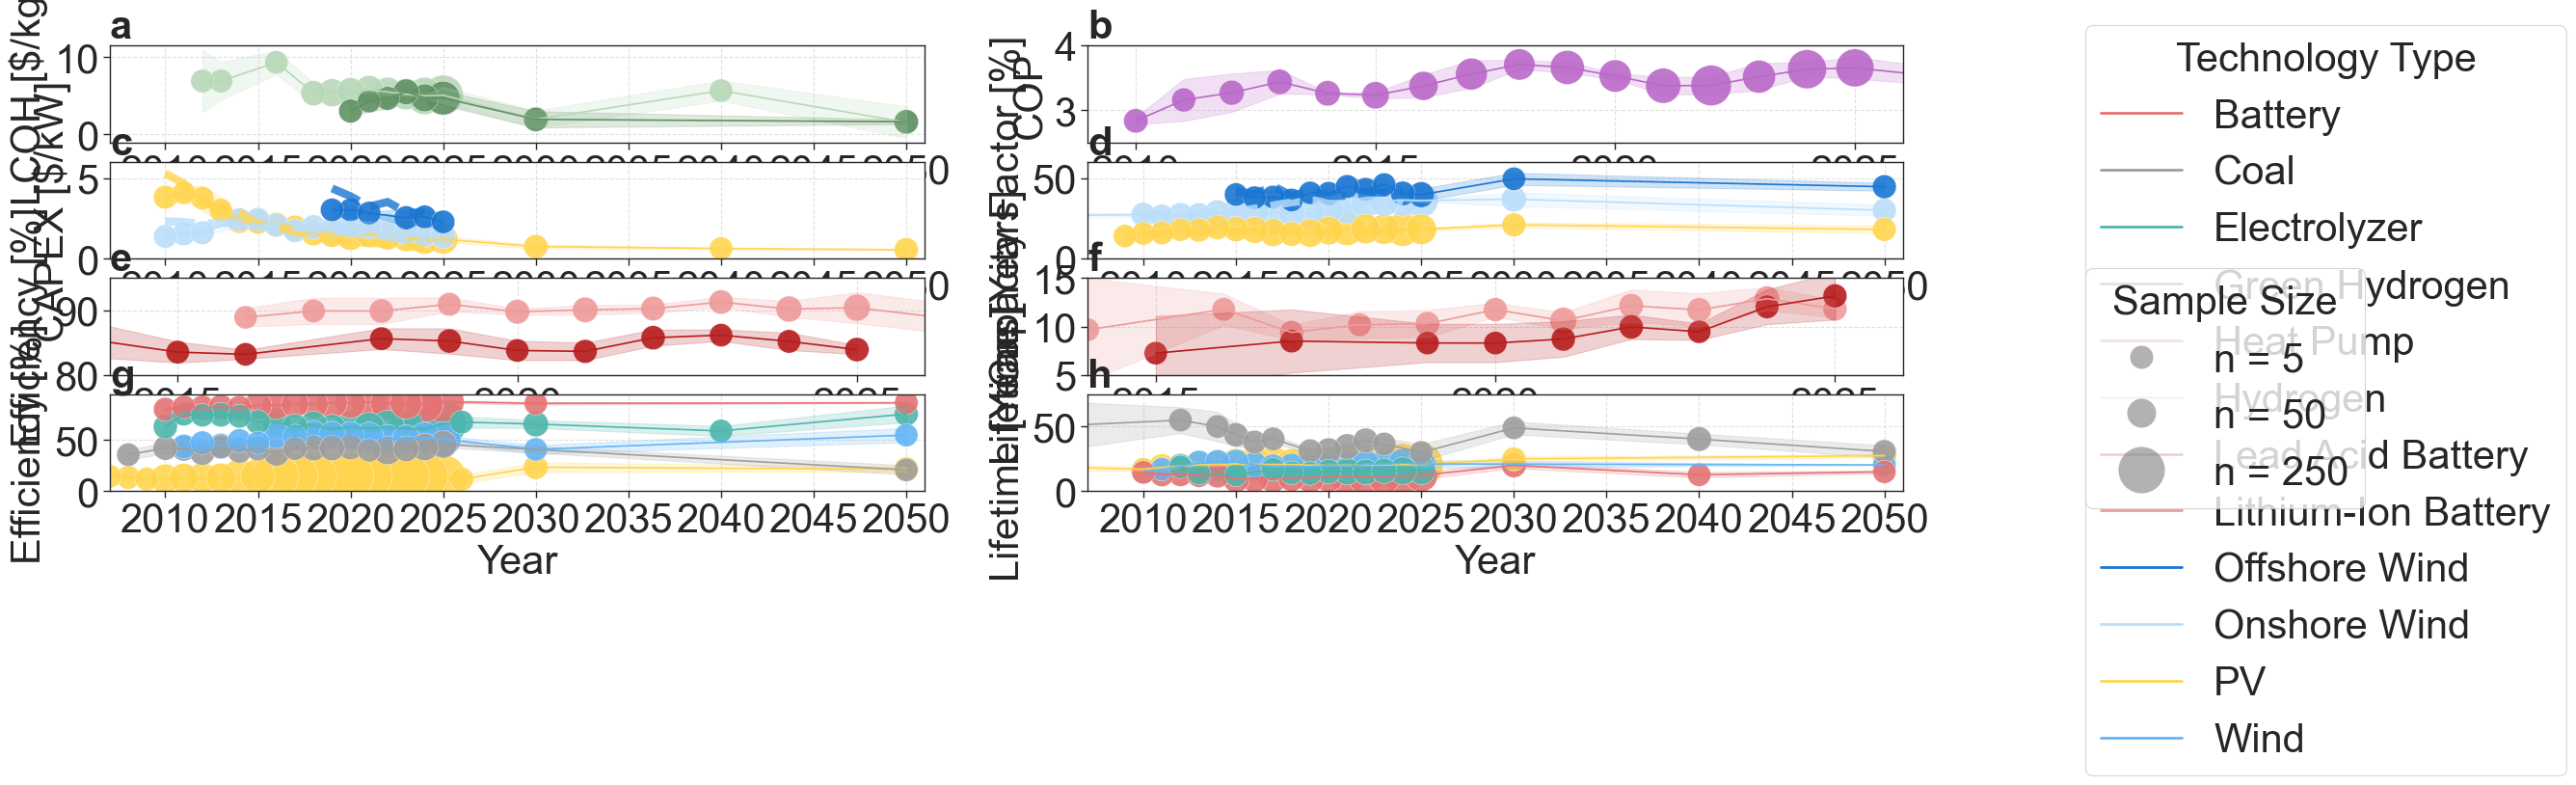

In [21]:
cost_capex['entity_mapping'] = cost_capex['entity_mapping'].replace({
    'Wind': 'Onshore Wind'
})
cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({
    'Wind': 'Onshore Wind'
})
print(len(cap_factor[cap_factor["entity_mapping"].isin((['Onshore Wind']))]))

df_sample = cap_factor[cap_factor['entity_mapping'] == 'Onshore Wind'].sample(n=500)
df_sample = df_sample.applymap(
    lambda x: f"'{x}" if isinstance(x, str) and x.startswith('=') else x
)
df_sample.to_csv("capfactor_data_500.csv", index=False, sep=';', decimal=',')

data = [
    {
    'df': cost_lcoh[cost_lcoh["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_converted',
    'ylabel': 'LCOH [$/kg]', 
    'title': 'a',
    'year_range': (2007, 2051),
    # 'y_range': (0, 6),
    },
    {
    'df': cop[cop["entity_mapping"].isin(['Heat Pump'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'COP', 
    'title': 'b',
    'year_range': (2009, 2026),
    'y_range': (2.5, 4),
    },
    {
    'df': cost_capex[cost_capex["entity_mapping"].isin(['PV', 'Offshore Wind', 'Onshore Wind'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_converted',
    'ylabel': 'CAPEX [$/kW]', 
    'title': 'c',
    'additional_data': capex_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 6),
    },
    {
    'df': cap_factor[cap_factor["entity_mapping"].isin((['PV', 'Offshore Wind', 'Onshore Wind']))],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Capacity Factor [%]', 
    'title': 'd',
    'additional_data': cap_factor_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 60),
    },
    {
    'df': efficiency[efficiency["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'e',
    'year_range': (2014, 2026),
    'y_range': (80, 95),
    },
    {
    'df': lifetime[lifetime["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'f',
    'year_range': (2014, 2026),
    'y_range': (5, 15),
    },
    {
    'df': efficiency[efficiency["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'g',
    'year_range': (2007, 2051),
    'y_range': (0, 95),
    },
    {
    'df': lifetime[lifetime["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'h',
    'year_range': (2007, 2051),
    'y_range': (0, 75),
    },
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24,6),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 1200),
    min_papers_per_year=3,
    min_datapoints_per_year=3,
    bubble_value_clip=(5, 250),
    bubble_legend_values=[5, 50, 250],
    iqr_lower_quantile=0.25,
    iqr_upper_quantile=0.75,
    iqr_multiplier=3,
    )

fig.show()
#fig.savefig("../data/figures/results/temporal/technologies_properties.pdf", bbox_inches='tight')

In [13]:
pd.DataFrame(capex_additional_offshore)

,year,value,entity
0,2019,4.354,Offshore Wind
1,2020,3.870,Offshore Wind
2,2021,3.229,Offshore Wind
3,2022,3.518,Offshore Wind
4,2023,2.867,Offshore Wind
5,2024,2.852,Offshore Wind


In [14]:
df_pv = data_tables['c'][data_tables['c']['entity_mapping'] == 'Offshore Wind'].sort_values("jahr")
df_pv = df_pv[(df_pv["jahr"] > 2009) & (df_pv["jahr"] < 2025)]
df_pv[['jahr', 'value_central']]

,jahr,value_central
9,2019,3.026546
10,2020,3.026969
11,2021,2.826854
13,2023,2.535849
14,2024,2.594008


In [15]:
build_log_regression_metric_labels(
    fit_df=df_pv,
    entity_col='entity_mapping',
    additional_df = pd.DataFrame(capex_additional_offshore)
)

['Offshore Wind: -3.75%/yr', 'Offshore Wind_Additional: -8.03%/yr | MAE=0.6']

### **Number of Nodes**

In [16]:
df = pd.read_parquet("../data/visualisation_files/df_technologies_nan.parquet")

In [17]:
number_nodes = df[df["property_mapping"] == "Number of Nodes"]
number_nodes = number_nodes[number_nodes['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') in ['http://qudt.org/vocab/unit/UNITLESS', 'http://qudt.org/vocab/unit/KN']
)]
print(number_nodes["unit_normalized"].value_counts())
number_nodes.drop(columns=["temporal_scope"], errors="ignore", inplace=True)
number_nodes["temporal_scope"] = pd.NA
number_nodes["neue_spalte"] = "Number of Nodes"

unit_normalized
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]                 3587
[{'exponent': 1.0, 'text': 'node', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]                      3387
[{'exponent': 1.0, 'text': 'nodes', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]                     2331
[{'exponent': 1.0, 'text': 'Node', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]                        27
[{'exponent': 1.0, 'text': 'Nodes', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]                        8
[{'exponent': 1.0, 'text': 'nodes (layers)', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]               1
[{'exponent': 1.0, 'text': '(green) node', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]                 1
[{'exponent': 1.0, 'text': 'nodes (categories)', 'unit_uri': 'http://qudt.org/vocab/unit/KN', 'year': None}]           1
[{'exponent': 1.

In [18]:
number_time = df[df["property_mapping"] == "Number of Time Steps"]
number_time = number_time[number_time['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') in ['http://qudt.org/vocab/unit/UNITLESS']
)]
print(number_time["unit_normalized"].value_counts())
number_time.drop(columns=["temporal_scope"], errors="ignore", inplace=True)
number_time["temporal_scope"] = pd.NA
number_time["neue_spalte"] = "Number of Time Steps"

unit_normalized
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]    2155
Name: count, dtype: int64



=== Temporal Plot Generation Summary ===
[1] a | IQR removed: 1084 values (before=9341, after=8257)
    Contributing studies (DOI): 2802 unique DOI(s)
[2] b | IQR removed: 422 values (before=2153, after=1731)
    Contributing studies (DOI): 946 unique DOI(s)
Total contributing studies in this generated figure: 3616 unique DOI(s)


C:\Users\m.gorres\AppData\Local\Temp\ipykernel_13328\77597450.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


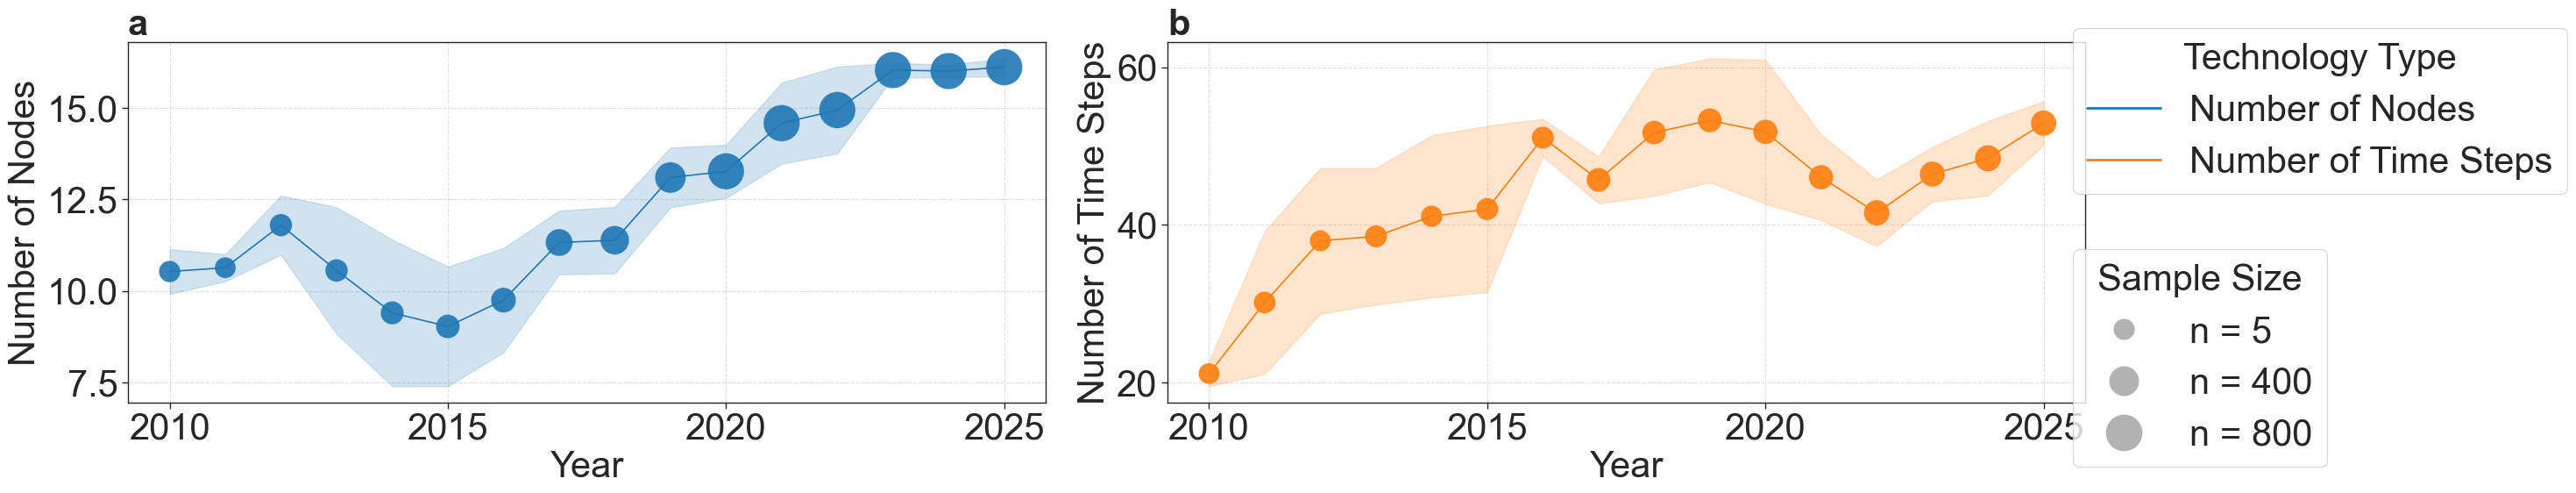

In [19]:
data = [
    {
    'df': number_nodes[number_nodes["publication_year"] < 2026],
    'entity_col': 'neue_spalte',
    'value_col': 'value_normalized',
    'ylabel': 'Number of Nodes', 
    'title': 'a',
    # 'year_range': (2007, 2051),
    #'y_range': (5, 16),
    },
    {
    'df': number_time[number_time["publication_year"] < 2026],
    'entity_col': 'neue_spalte',
    'value_col': 'value_normalized',
    'ylabel': 'Number of Time Steps', 
    'title': 'b',
    # 'year_range': (2007, 2051),
    # 'y_range': (0, 7),
    },
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    #color_dict=visualisation.entity_colors,
    figsize=(24,6),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 900),
    min_papers_per_year=3,
    min_datapoints_per_year=3,
    bubble_value_clip=(5, 800),
    bubble_legend_values=[5, 400, 800],
    iqr_lower_quantile=0.25,
    iqr_upper_quantile=0.75,
    iqr_multiplier=3,
    )

fig.show()
fig.savefig("../data/figures/results/temporal/number_nodes_timesteps.pdf", bbox_inches='tight')

In [20]:
number_scenarios = df[df["property_mapping"] == "Number of Scenarios"]
number_scenarios = number_scenarios[number_scenarios['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') in ['http://qudt.org/vocab/unit/UNITLESS']
)]
number_scenarios["unit_normalized"].value_counts()
number_scenarios = visualisation.convert_spatial(number_scenarios, spatial_col="spatial_scope")
number_scenarios["neue_spalte"] = "Number of Time Steps"
print(number_scenarios["property_base_mapping"].value_counts())

number_scenarios = apply_iqr_filter(number_scenarios, value_column="value_normalized", group_column="neue_spalte", iqr_multiplier=3)
number_nodes = apply_iqr_filter(number_nodes, value_column="value_normalized", group_column="neue_spalte", iqr_multiplier=3)
number_time = apply_iqr_filter(number_time, value_column="value_normalized", group_column="neue_spalte", iqr_multiplier=3)

all_dois = set(
    pd.concat([
        number_scenarios["DOI"],
        number_nodes[number_nodes["publication_year"] < 2026]["DOI"],
        number_time[number_time["publication_year"] < 2026]["DOI"]
    ])
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Anzahl unterschiedlicher Publikationen in den 3 DataFrames:", len(all_dois))

AttributeError: 'TemporalVisualisation' object has no attribute 'convert_spatial'

In [ ]:
lifetime[(lifetime["entity_mapping"] == "Coal") & (lifetime["value_normalized"] < 15)]